In [9]:
import time
import seaborn as sns
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import pickle

In [2]:
from sklearn.feature_selection import mutual_info_classif
from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import train_test_split
from sklearn.metrics import classification_report, confusion_matrix, roc_auc_score
from sklearn.preprocessing import label_binarize

from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Conv1D, MaxPooling1D, Flatten, Dense, Dropout
from tensorflow.keras.optimizers import Adam, RMSprop, SGD
from tensorflow.keras.regularizers import l2
from tensorflow.keras.utils import plot_model
from tensorflow.keras.callbacks import EarlyStopping, ModelCheckpoint

2025-06-29 22:37:32.602080: W tensorflow/stream_executor/platform/default/dso_loader.cc:64] Could not load dynamic library 'libcudart.so.11.0'; dlerror: libcudart.so.11.0: cannot open shared object file: No such file or directory
2025-06-29 22:37:32.602129: I tensorflow/stream_executor/cuda/cudart_stub.cc:29] Ignore above cudart dlerror if you do not have a GPU set up on your machine.


In [3]:
# Load the preprocessed dataset
df = pd.read_csv('../../Edge-IIoTset_DNN-112.csv')

In [4]:
print(df['Attack_type'].value_counts())

Attack_type
Normal                   1399624
DDoS_UDP                  121567
DDoS_ICMP                  67939
SQL_injection              50826
DDoS_TCP                   50062
Vulnerability_scanner      50026
Password                   49933
DDoS_HTTP                  48544
Uploading                  36957
Backdoor                   24026
Port_Scanning              19977
XSS                        15068
Ransomware                  9689
Fingerprinting               853
MITM                         358
Name: count, dtype: int64


In [5]:
# Creating a dictionary of Types
attacks = {'Normal': 0,'MITM': 1, 'Uploading': 2, 'Ransomware': 3, 'SQL_injection': 4,
       'DDoS_HTTP': 5, 'DDoS_TCP': 6, 'Password': 7, 'Port_Scanning': 8,
       'Vulnerability_scanner': 9, 'Backdoor': 10, 'XSS': 11, 'Fingerprinting': 12,
       'DDoS_UDP': 13, 'DDoS_ICMP': 14}
df['Attack_type'] = df['Attack_type'].map(attacks)

In [6]:
X = df.drop(columns=['Attack_label', 'Attack_type'])
y = df['Attack_type']

In [7]:
print(df['Attack_type'].value_counts())

Attack_type
0     1399624
13     121567
14      67939
4       50826
6       50062
9       50026
7       49933
5       48544
2       36957
10      24026
8       19977
11      15068
3        9689
12        853
1         358
Name: count, dtype: int64


In [10]:
# Load precomputed selected features
feature_list_path = "selected_features_15class_mi.pkl"
with open(feature_list_path, "rb") as f:
    selected_features = pickle.load(f)

In [11]:
k = 30
selected_features = selected_features[:k]

In [12]:
# Split the data into train (80%) and test (20%) sets
X_train, X_test, y_train, y_test = train_test_split(X[selected_features], y, test_size=0.4, random_state=42)

# Split the training data further into train (80%) and validation (20%) sets
X_train, X_val, y_train, y_val = train_test_split(X_train, y_train, test_size=0.10, random_state=42)

In [13]:
print("X_train shape:", X_train.shape)
print("X_val shape:", X_val.shape)
print("X_test shape:", X_test.shape)

X_train shape: (1050542, 30)
X_val shape: (116727, 30)
X_test shape: (778180, 30)


In [14]:
scaler = StandardScaler().fit(X_train)
X_train = scaler.transform(X_train)
X_val = scaler.transform(X_val)
X_test = scaler.transform(X_test)

In [15]:
best_params = {
    "filters": 128,
    "dense_units": 128,
    "kernel_size": 7,
    "dropout_rate": 0.2,
    "learning_rate": 0.0001,
}

best_fit_params = {
    "batch_size": 32,
    "epochs": 50,
}

In [16]:
# Initialize the 1D CNN classifier
def model_1d_cnn(
        input_shape,
        num_classes=15,
        filters=64,
        kernel_size=3,
        pool_size=2,
        dropout_rate=0.5,
        dense_units=100,
        learning_rate=1e-3,
        optimizer="adam",
        l2_reg=0.0,
):
    _model = Sequential([
        Conv1D(filters=filters,
               kernel_size=kernel_size,
               activation="relu",
               kernel_regularizer=l2(l2_reg),
               input_shape=input_shape),
        MaxPooling1D(pool_size=pool_size),
        Dropout(dropout_rate),
        Flatten(),
        Dense(dense_units, activation="relu"),
    ])

    if num_classes == 2:
        _model.add(Dense(1, activation="sigmoid"))
        loss = "binary_crossentropy"
    else:
        _model.add(Dense(num_classes, activation="softmax"))
        loss = "sparse_categorical_crossentropy"

    # choose optimiser
    if optimizer == "adam":
        opt = Adam(learning_rate=learning_rate)
    elif optimizer == "rmsprop":
        opt = RMSprop(learning_rate=learning_rate)
    elif optimizer == "sgd":
        opt = SGD(learning_rate=learning_rate, momentum=0.9)
    else:
        raise ValueError("Unknown optimiser.")

    _model.compile(optimizer=opt, loss=loss, metrics=["accuracy"])
    return _model


2025-06-29 22:38:42.973300: I tensorflow/stream_executor/cuda/cuda_gpu_executor.cc:939] successful NUMA node read from SysFS had negative value (-1), but there must be at least one NUMA node, so returning NUMA node zero
2025-06-29 22:38:42.975255: W tensorflow/stream_executor/platform/default/dso_loader.cc:64] Could not load dynamic library 'libcudart.so.11.0'; dlerror: libcudart.so.11.0: cannot open shared object file: No such file or directory
2025-06-29 22:38:42.975660: W tensorflow/stream_executor/platform/default/dso_loader.cc:64] Could not load dynamic library 'libcublas.so.11'; dlerror: libcublas.so.11: cannot open shared object file: No such file or directory
2025-06-29 22:38:42.975878: W tensorflow/stream_executor/platform/default/dso_loader.cc:64] Could not load dynamic library 'libcublasLt.so.11'; dlerror: libcublasLt.so.11: cannot open shared object file: No such file or directory
2025-06-29 22:38:42.976224: W tensorflow/stream_executor/platform/default/dso_loader.cc:64] Co

Model: "sequential"
_________________________________________________________________
 Layer (type)                Output Shape              Param #   
 conv1d (Conv1D)             (None, 24, 128)           1024      
                                                                 
 max_pooling1d (MaxPooling1D  (None, 12, 128)          0         
 )                                                               
                                                                 
 dropout (Dropout)           (None, 12, 128)           0         
                                                                 
 flatten (Flatten)           (None, 1536)              0         
                                                                 
 dense (Dense)               (None, 128)               196736    
                                                                 
 dense_1 (Dense)             (None, 15)                1935      
                                                        

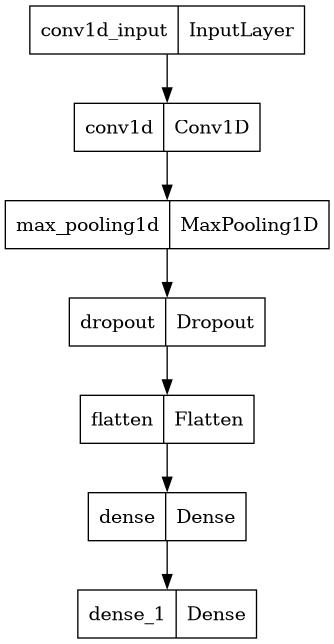

In [17]:
input_shape = (X_train.shape[1], 1)
num_classes = 15
model = model_1d_cnn(input_shape=input_shape,
                     num_classes=num_classes,
                     **best_params)
model.summary()
plot_model(model)

In [18]:
early_stop = EarlyStopping(
        monitor="val_loss",
        patience=10,
        restore_best_weights=True,
        verbose=1
)
model_checkpoint = ModelCheckpoint("1D-CNN2_15" + '.h5',
                     monitor='val_accuracy',
                     mode='max',
                     verbose=1,
                     save_best_only=True)

In [19]:
train_start_time = time.time()
# Train the model
history = model.fit(X_train, y_train,
                    validation_data=(X_val, y_val),
                    epochs=best_fit_params['epochs'],
                    batch_size=best_fit_params['batch_size'],
                    callbacks=[early_stop, model_checkpoint])

# Record the ending time
train_end_time = time.time()

# Record the starting time for testing
test_start_time = time.time()
# Evaluate the model
loss, accuracy = model.evaluate(X_test, y_test, batch_size=best_fit_params['batch_size'])
# Record the ending time for testing
test_end_time = time.time()

print(f'Test Loss: {loss:.4f}')
print(f'Test Accuracy: {accuracy:.4f}')

# Calculate and print the training time
train_time = train_end_time - train_start_time
print(f"Training time: {train_time:.2f} seconds")

# Calculate and print the testing time
test_time = test_end_time - test_start_time
print(f"Testing time: {test_time:.2f} seconds")

Epoch 1/50
32829/32830 [============================>.] - ETA: 0s - loss: 0.1485 - accuracy: 0.9339
Epoch 00001: val_accuracy improved from -inf to 0.94826, saving model to 1D-CNN2_15.h5
32830/32830 [==============================] - 221s 7ms/step - loss: 0.1485 - accuracy: 0.9339 - val_loss: 0.1102 - val_accuracy: 0.9483
Epoch 2/50
32824/32830 [============================>.] - ETA: 0s - loss: 0.1049 - accuracy: 0.9520
Epoch 00002: val_accuracy improved from 0.94826 to 0.95427, saving model to 1D-CNN2_15.h5
32830/32830 [==============================] - 223s 7ms/step - loss: 0.1049 - accuracy: 0.9520 - val_loss: 0.0963 - val_accuracy: 0.9543
Epoch 3/50
32828/32830 [============================>.] - ETA: 0s - loss: 0.0949 - accuracy: 0.9562
Epoch 00003: val_accuracy improved from 0.95427 to 0.95878, saving model to 1D-CNN2_15.h5
32830/32830 [==============================] - 207s 6ms/step - loss: 0.0949 - accuracy: 0.9562 - val_loss: 0.0885 - val_accuracy: 0.9588
Epoch 4/50
32827/32830

In [20]:
n_samples = min(100, len(X_test))
total_time = 0.0

for i in range(n_samples):
    sample = X_test[i].reshape(1, -1, 1)  # Shape: (1, features, 1)
    start_time = time.time()
    _ = model.predict(sample, verbose=0)
    total_time += time.time() - start_time

avg_inference_time = total_time / n_samples
print(f"Average inference time per sample: {avg_inference_time:.6f} seconds")

Average inference time per sample: 0.070027 seconds


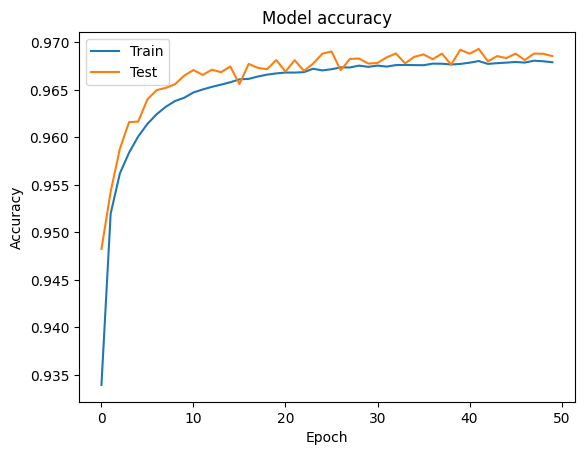

In [21]:
plt.plot(history.history['accuracy'])
plt.plot(history.history['val_accuracy'])
plt.title('Model accuracy')
plt.ylabel('Accuracy')
plt.xlabel('Epoch')
plt.legend(['Train', 'Test'], loc='upper left')
plt.show()

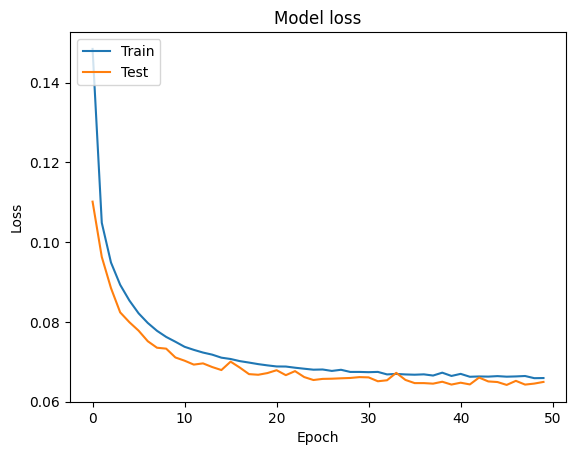

In [22]:
# Plot the training and validation loss over the epochs
plt.plot(history.history['loss'])
plt.plot(history.history['val_loss'])
plt.title('Model loss')
plt.ylabel('Loss')
plt.xlabel('Epoch')
plt.legend(['Train', 'Test'], loc='upper left')
plt.show()
# plt.savefig('los_plo.jpg')

In [23]:
y_pred = model.predict(np.expand_dims(X_test, axis=2))

In [24]:
y_pred_classes = np.argmax(y_pred, axis=1)

# Inverse the 'attacks' dictionary to map back numbers to names
inverse_attacks = {v: k for k, v in attacks.items()}

# Generate the classification report with attack names instead of numbers
class_report = classification_report(y_test, y_pred_classes, target_names=[inverse_attacks[i] for i in range(len(inverse_attacks))])

print(class_report)

                       precision    recall  f1-score   support

               Normal       1.00      1.00      1.00    560180
                 MITM       1.00      1.00      1.00       133
            Uploading       0.87      0.69      0.77     14756
           Ransomware       0.95      0.94      0.95      3952
        SQL_injection       0.57      1.00      0.72     20271
            DDoS_HTTP       0.94      0.88      0.91     19479
             DDoS_TCP       0.98      0.93      0.96     19942
             Password       0.96      0.36      0.53     19939
        Port_Scanning       0.85      1.00      0.92      7988
Vulnerability_scanner       0.99      0.92      0.95     20212
             Backdoor       0.99      0.96      0.97      9593
                  XSS       0.62      0.89      0.73      6128
       Fingerprinting       0.85      0.54      0.66       358
             DDoS_UDP       1.00      1.00      1.00     48340
            DDoS_ICMP       1.00      1.00      1.00  

In [25]:
# Get detailed report as a dictionary
report_dict = classification_report(
    y_test,
    y_pred_classes,
    target_names=[inverse_attacks[i] for i in range(len(inverse_attacks))],
    output_dict=True
)

# Convert to DataFrame and format with more floats
report_df = pd.DataFrame(report_dict).T  # transpose for better layout
report_df = report_df.round(4)  # round to 4 decimal places

print(report_df)

                       precision  recall  f1-score      support
Normal                    1.0000  1.0000    1.0000  560180.0000
MITM                      1.0000  1.0000    1.0000     133.0000
Uploading                 0.8745  0.6894    0.7710   14756.0000
Ransomware                0.9495  0.9418    0.9456    3952.0000
SQL_injection             0.5652  0.9975    0.7216   20271.0000
DDoS_HTTP                 0.9436  0.8847    0.9132   19479.0000
DDoS_TCP                  0.9840  0.9322    0.9574   19942.0000
Password                  0.9590  0.3637    0.5273   19939.0000
Port_Scanning             0.8545  0.9999    0.9215    7988.0000
Vulnerability_scanner     0.9893  0.9220    0.9544   20212.0000
Backdoor                  0.9863  0.9627    0.9744    9593.0000
XSS                       0.6231  0.8869    0.7319    6128.0000
Fingerprinting            0.8458  0.5363    0.6564     358.0000
DDoS_UDP                  0.9993  0.9999    0.9996   48340.0000
DDoS_ICMP                 0.9956  0.9977

In [26]:
# Binarize the true labels for multi-class AUC
y_test_bin = label_binarize(y_test, classes=list(attacks.values()))  # shape: (n_samples, n_classes)

# y_pred is already the softmax output: shape (n_samples, n_classes)
auc_macro = roc_auc_score(y_test_bin, y_pred, average='macro', multi_class='ovr')
auc_weighted = roc_auc_score(y_test_bin, y_pred, average='weighted', multi_class='ovr')

print(f"AUC (macro-averaged OvR): {auc_macro:.4f}")
print(f"AUC (weighted-averaged OvR): {auc_weighted:.4f}")

AUC (macro-averaged OvR): 0.9984
AUC (weighted-averaged OvR): 0.9995


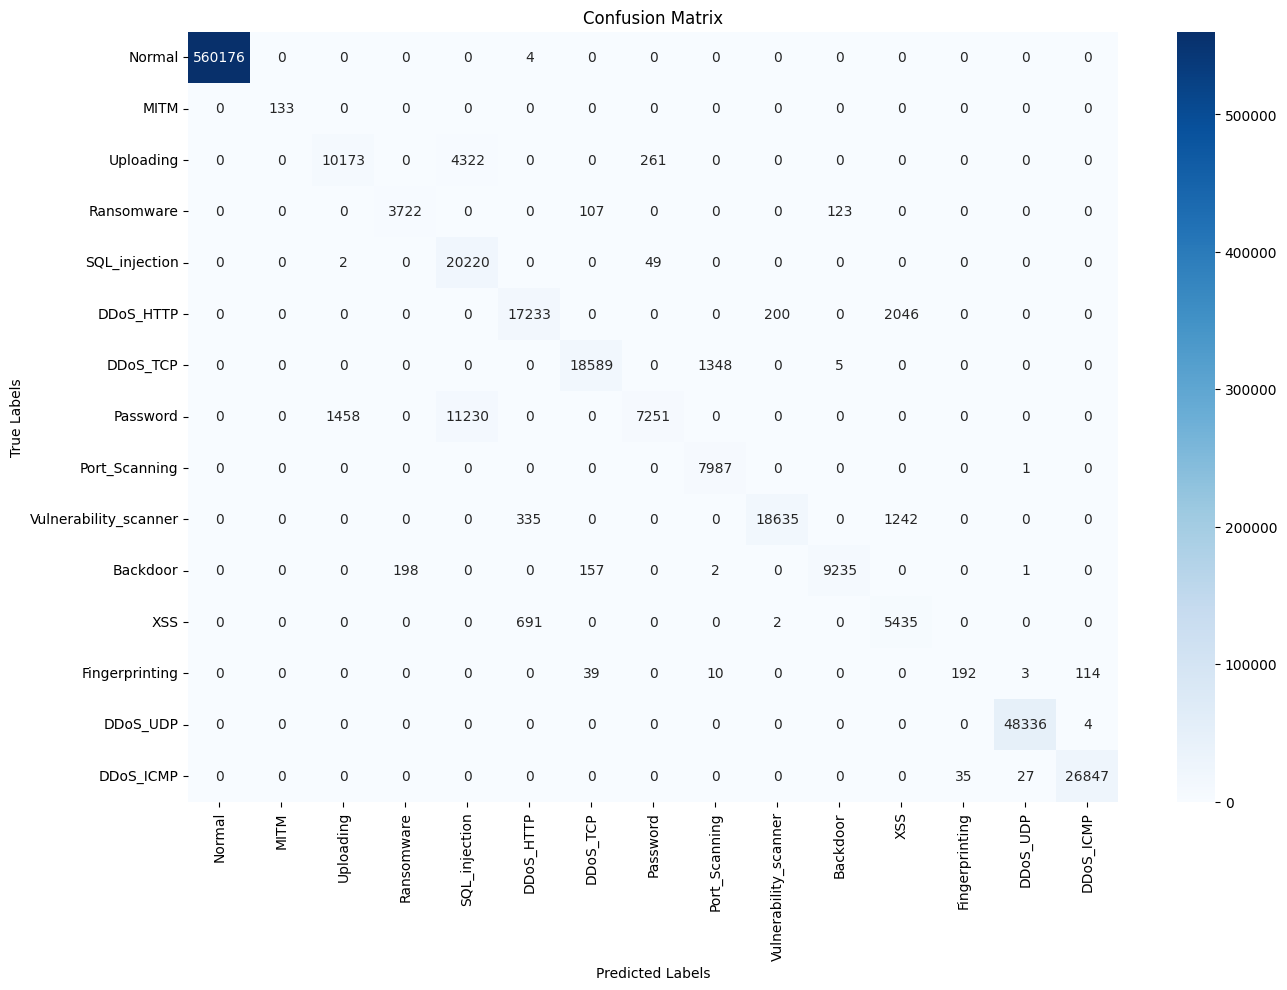

In [27]:
# Compute the confusion matrix
conf_mat = confusion_matrix(y_test, y_pred_classes)

# Convert the 'attacks' dictionary to a list of class names ordered by the class number
class_names_ordered = [attack for attack, number in sorted(attacks.items(), key=lambda item: item[1])]

# Plot the heatmap using seaborn
plt.figure(figsize=(15, 10))
sns.heatmap(conf_mat, annot=True, fmt="d", cmap="Blues", xticklabels=class_names_ordered, yticklabels=class_names_ordered)
plt.xlabel('Predicted Labels')
plt.ylabel('True Labels')
plt.title('Confusion Matrix')
plt.show()
# plt.savefig('con_mat.jpg')

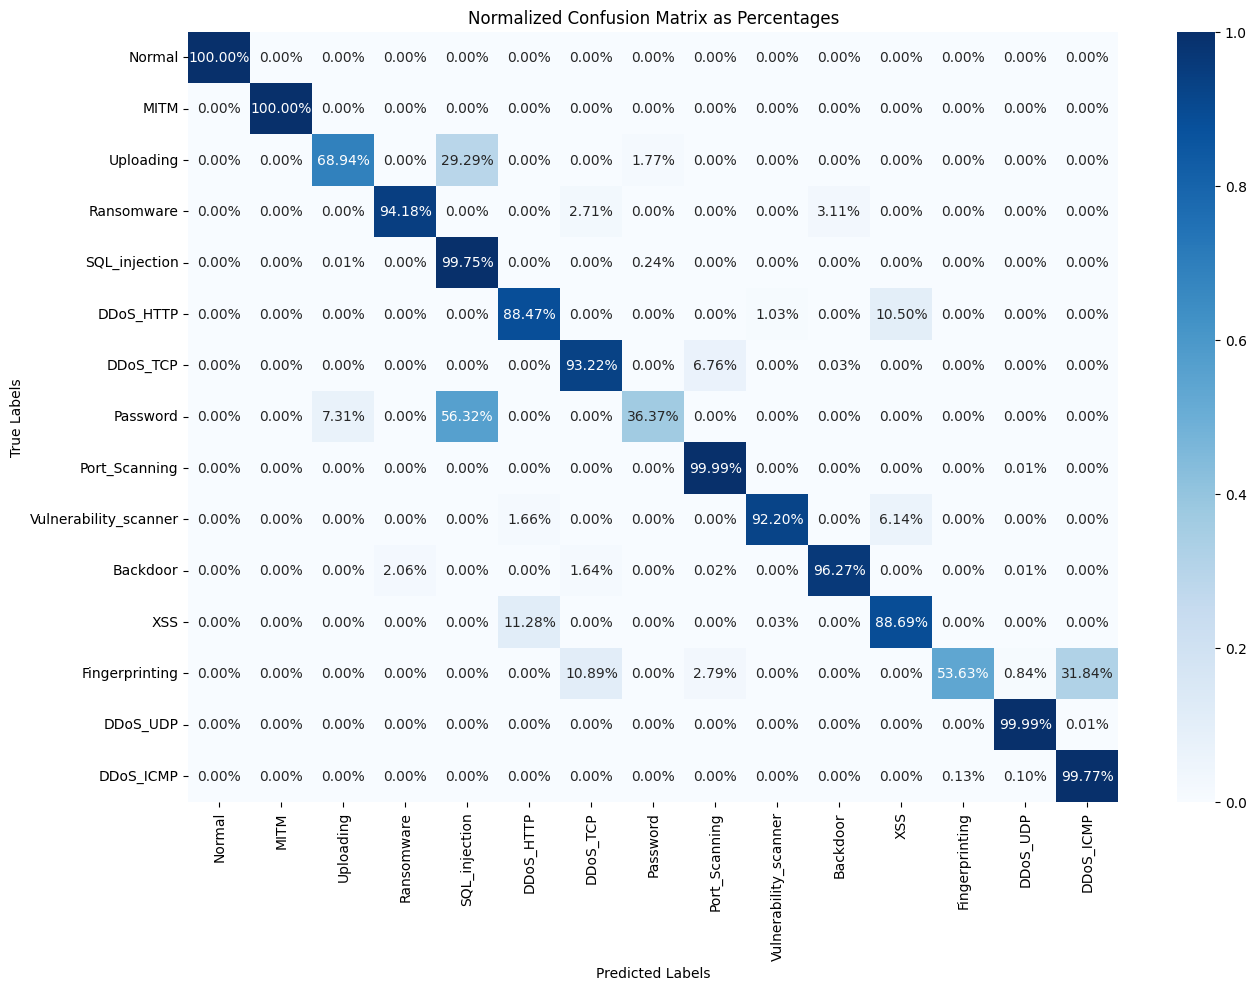

In [28]:
# Compute the confusion matrix
conf_mat = confusion_matrix(y_test, y_pred_classes)

# Normalize the confusion matrix by dividing each value by the sum of its row (i.e., the number of true instances for each label)
conf_mat_normalized = conf_mat.astype('float') / conf_mat.sum(axis=1)[:, np.newaxis]

# Convert the 'attacks' dictionary to a list of class names ordered by the class number
class_names_ordered = [attack for attack, number in sorted(attacks.items(), key=lambda item: item[1])]

# Plot the heatmap using seaborn
plt.figure(figsize=(15, 10))
sns.heatmap(conf_mat_normalized, annot=True, fmt=".2%", cmap="Blues", xticklabels=class_names_ordered, yticklabels=class_names_ordered)
plt.xlabel('Predicted Labels')
plt.ylabel('True Labels')
plt.title('Normalized Confusion Matrix as Percentages')
plt.show()
# plt.savefig('con_per.jpg')